# **Weiss-Vopat, Emerson** #

#### Analysis Report - 11/15/26 ####

##### **Dataset used:** *World Countries* (https://jsonlint.com/datasets/european-countries) #####

**Reason:** Truthfully, I used this dataset because the World Countries dataset had caught my eye when I initially scrolled on the JSON list simply because of the "50+" in the description. After noticing it, I was curious what other country datasets were out there, and the only other was the European Countries dataset (outside of World Currencies). After looking through it a bit it seemed like it would be something interesting to delve into so I decided to use it. Not unlike anyone else, I sometimes find it interesting to look into certain statistics regarding other countries in which I do not live, so I saw this as an excuse to do so for this project.

**Observation:** Each observation represents european countries alongside other geographic/demographic data

**Variables:** I plan to investigate several variables; population, eu_member, currency, and area_km2

- population defines the population count for a given country
- eu_member defines whether a given country is part of the European Union
- area_km2 defines the total area of a given country
- ~~currency defines the standard currency for a given country~~

*Note: I initially wanted to see if there is at all a correlation between the type of currency and the population of European countries in the EU and European countries that are not, but I ran into several problems with code (so much so that I believe there is some unnecessary code in this project, but after trying to clean it up I did more harm than good - also I did not have a hypothesis that I feel could follow both parts of my research question) and did not want to rely on AI to finish the project so I redid my scatter graph and went with the regression model instead.*

**Research Question:** Do countries in the European Union have a higher population than those who are not? ~~Does the population count correlate with the type of currency used?~~

**Hypothesis:** European countries in the European Union have a lower population than European countries whom are not in the European Union.

**Additional Resources Used:** https://www.youtube.com/c/PooyaMohammadiKazaj, https://www.geeksforgeeks.org/machine-learning/interpreting-the-results-of-linear-regression-using-ols-summary/, and 3 google searches were used to troubleshoot minor code issues regarding some variables (which will be noted in the cells they were used for).

In [175]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.formula.api import ols

df = pd.read_json("european-countries.json")

display(df.head())
print(df.columns)

# Initial Import

,countries
0,"{'name': 'Albania', 'code': 'AL', 'capital': '..."
1,"{'name': 'Andorra', 'code': 'AD', 'capital': '..."
2,"{'name': 'Austria', 'code': 'AT', 'capital': '..."
3,"{'name': 'Belarus', 'code': 'BY', 'capital': '..."
4,"{'name': 'Belgium', 'code': 'BE', 'capital': '..."


Index(['countries'], dtype='str')


In [176]:
df.info() # gives structure summary

# Initial Data Check 1

<class 'pandas.DataFrame'>
RangeIndex: 43 entries, 0 to 42
Data columns (total 1 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   countries  43 non-null     object
dtypes: object(1)
memory usage: 476.0+ bytes


In [177]:
df.describe() # gives statistic summary

# Initial Data Check 2

,countries
count,43
unique,43
top,"{'name': 'Albania', 'code': 'AL', 'capital': '..."
freq,1


In [178]:
import pandas as pd 
import matplotlib.pyplot as plt
import json

with open("european-countries.json", "r") as file: 
    data = json.load(file)

df = pd.DataFrame(data["countries"])

display(df.head())
print(df.columns)

# Initial Import

,name,code,capital,population,area_km2,eu_member,currency
0,Albania,AL,Tirana,2877797,28748.0,False,ALL
1,Andorra,AD,Andorra la Vella,77265,468.0,False,EUR
2,Austria,AT,Vienna,9006398,83879.0,True,EUR
3,Belarus,BY,Minsk,9449323,207600.0,False,BYN
4,Belgium,BE,Brussels,11589623,30528.0,True,EUR


Index(['name', 'code', 'capital', 'population', 'area_km2', 'eu_member',
       'currency'],
      dtype='str')


In [179]:
member = [
    country["population"]
    for country in data["countries"]
    if country.get("eu_member") is True
]

non_member = [
    country["population"]
    for country in data["countries"]
    if country.get("eu_member") is False
]

# Sources: YT and google search to fix if section

In [180]:
data['countries'][:10] # used to get a general idea of what is stored

[{'name': 'Albania',
  'code': 'AL',
  'capital': 'Tirana',
  'population': 2877797,
  'area_km2': 28748,
  'eu_member': False,
  'currency': 'ALL'},
 {'name': 'Andorra',
  'code': 'AD',
  'capital': 'Andorra la Vella',
  'population': 77265,
  'area_km2': 468,
  'eu_member': False,
  'currency': 'EUR'},
 {'name': 'Austria',
  'code': 'AT',
  'capital': 'Vienna',
  'population': 9006398,
  'area_km2': 83879,
  'eu_member': True,
  'currency': 'EUR'},
 {'name': 'Belarus',
  'code': 'BY',
  'capital': 'Minsk',
  'population': 9449323,
  'area_km2': 207600,
  'eu_member': False,
  'currency': 'BYN'},
 {'name': 'Belgium',
  'code': 'BE',
  'capital': 'Brussels',
  'population': 11589623,
  'area_km2': 30528,
  'eu_member': True,
  'currency': 'EUR'},
 {'name': 'Bosnia and Herzegovina',
  'code': 'BA',
  'capital': 'Sarajevo',
  'population': 3280819,
  'area_km2': 51197,
  'eu_member': False,
  'currency': 'BAM'},
 {'name': 'Bulgaria',
  'code': 'BG',
  'capital': 'Sofia',
  'population': 

In [181]:
countries_df = pd.DataFrame(data['countries'])
countries_df = countries_df[['name', 'population', 'area_km2', 'currency']]
countries_df.head() 

# Small data frame to get a glimpse at columns

,name,population,area_km2,currency
0,Albania,2877797,28748.0,ALL
1,Andorra,77265,468.0,EUR
2,Austria,9006398,83879.0,EUR
3,Belarus,9449323,207600.0,BYN
4,Belgium,11589623,30528.0,EUR


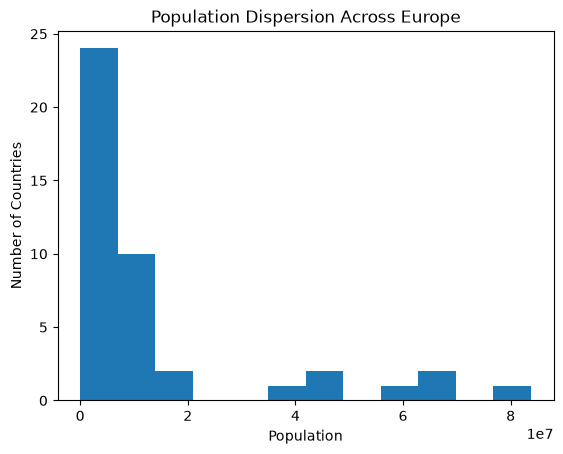

In [182]:
plt.hist(df["population"], bins=12) # matplotlib to recall population count 

plt.xlabel("Population") # x-axis title
plt.ylabel("Number of Countries") # y-axis title
plt.title("Population Dispersion Across Europe") # chart title

plt.show()

### Histogram Discussion: ###

This histogram showcases the population dispersion across Europe (including those not and in the European Union). It appears there are few European countries with large populations, the majority of which are quite small in comparison. Any less than 8 bins is far too small for this graph, as you cannot clearly see the differences.

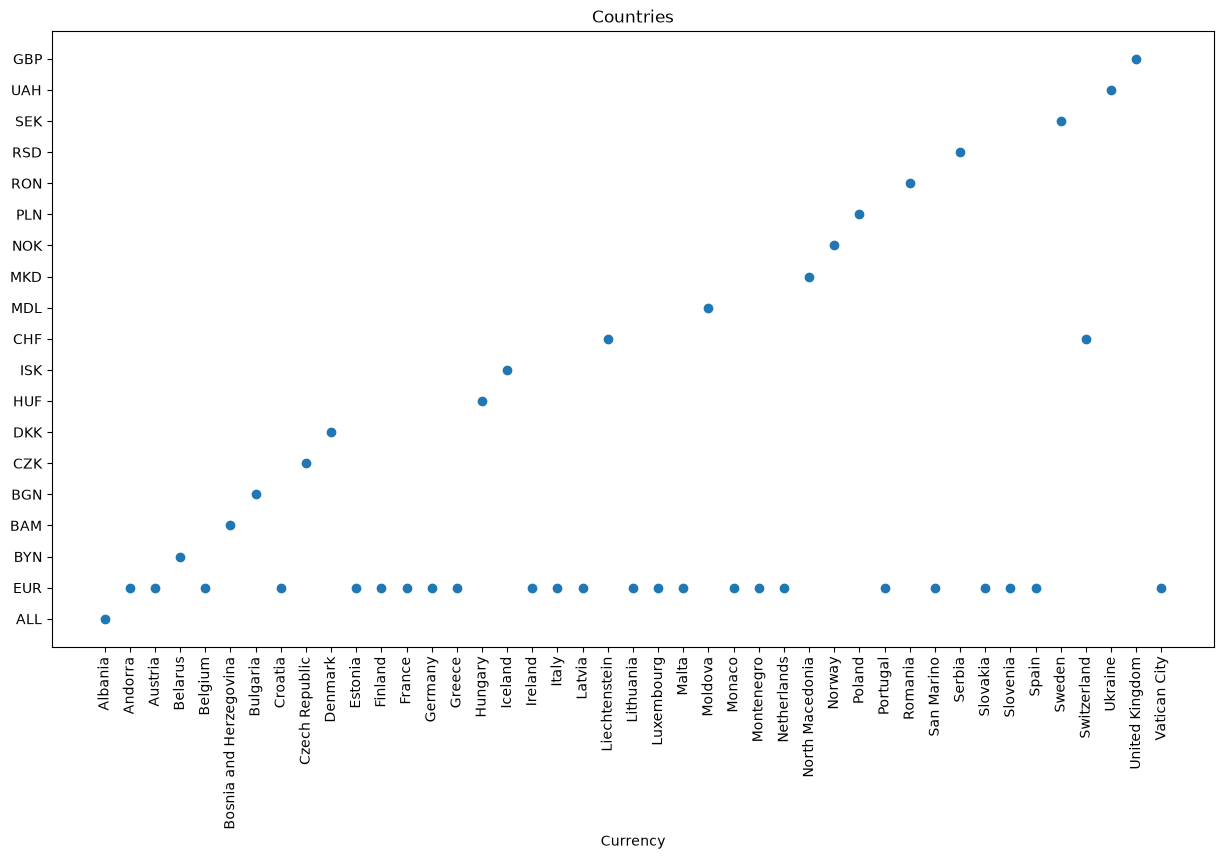

In [183]:
# *GRAPH NO LONGER IN USE*

plt.figure(figsize=(15,8)) # scales graph up to fit data

plt.scatter(df["name"],
            df["currency"])

plt.title("Countries") # graph title
plt.xlabel("Currency") # x-axis title
plt.ylabel("") # y-axis title
plt.xticks(rotation=90) # rotates countries so they are readable

plt.show()

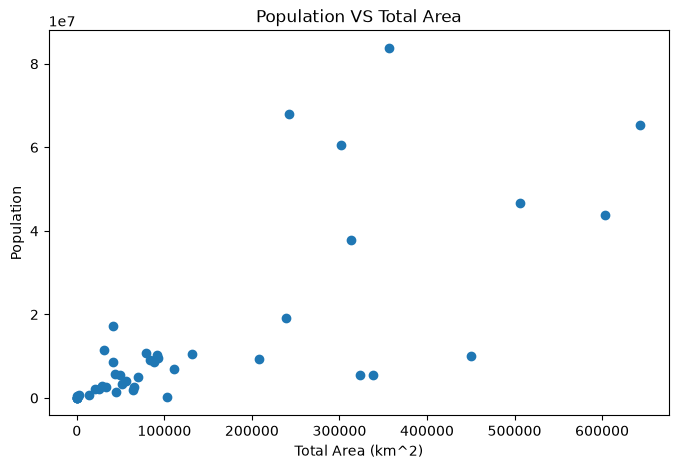

In [184]:
plt.figure(figsize=(8,5)) # scales graph to fit data

plt.scatter(df["area_km2"], # scatter graph consisting of area and population of countries
            df["population"])

plt.title("Population VS Total Area") # graph title
plt.xlabel("Total Area (km^2)") # x-axis title
plt.ylabel("Population") # y-axis title

plt.show()

### Scatter Discussion: ###

This scattersplot showcases further data, that being the total surface area of European countries and the population. It appears that countries with a smaller area tend to have a lower population.

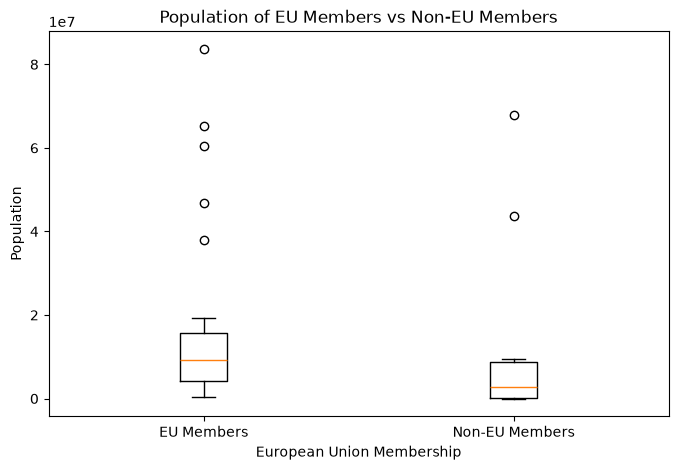

In [185]:
plt.figure(figsize=(8,5)) # scales graph to fit data

plt.boxplot([member, non_member], # box plot to compare European countries in the 
                                  # European Union and those that are not
                                  
    
    tick_labels=["EU Members", "Non-EU Members"] # labels EU members and Non-EU members
)

plt.xlabel("European Union Membership") # x-axis title
plt.ylabel("Population") # y-axis title
plt.title("Population of EU Members vs Non-EU Members") # graph title

plt.show()

### Box Plot Discussion: ###

This boxplot highlights two parties; European countries in the European Union, and European countries not in the European Union. Through this graph, it appears that countries in the European Union may generally have a higher population.

# Histogram (Improved) #

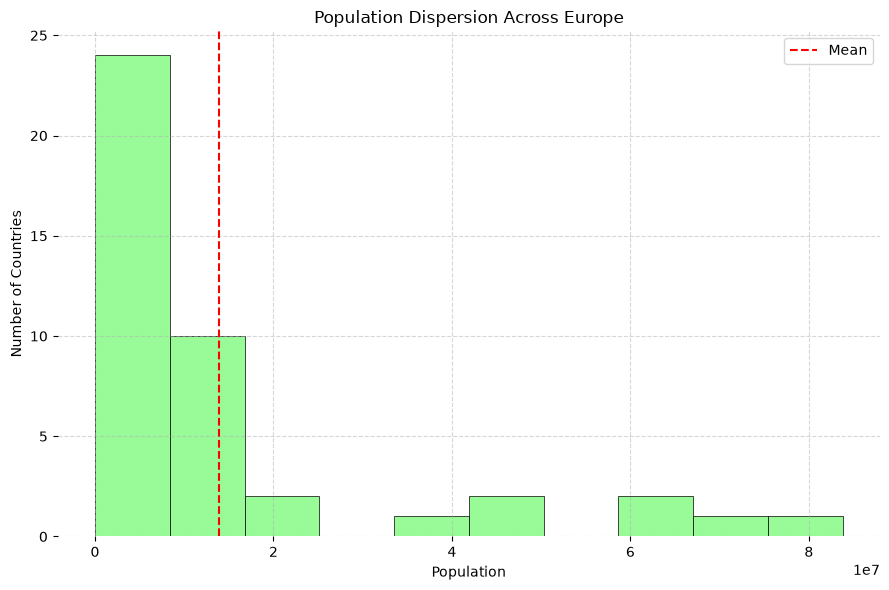

In [186]:
plt.figure(figsize=(9,6)) # increased size for general readability
                          # and consistency with other graphs

plt.hist(df["population"], bins=10, color="palegreen", edgecolor="black", linewidth=.5) 

# reduced to 10 bins to more accurately showcase data 
# color/edgecolor and lidewith for readability

plt.gca().spines[:].set_visible(False) # removed spines for simplicity
plt.xlabel("Population")
plt.ylabel("Number of Countries")
plt.title("Population Dispersion Across Europe")
plt.axvline(df["population"].mean(), color="red", linestyle="--", label="Mean") 

# included a meanline to give more context to data shown

plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

# legend to define meanline

plt.tight_layout() # while not strictly necessary for my data, 
                   # tightens layout to make data more concise
plt.show()

#Sources: Google to fix axvline code section

# Scatter Plot (Improved) #

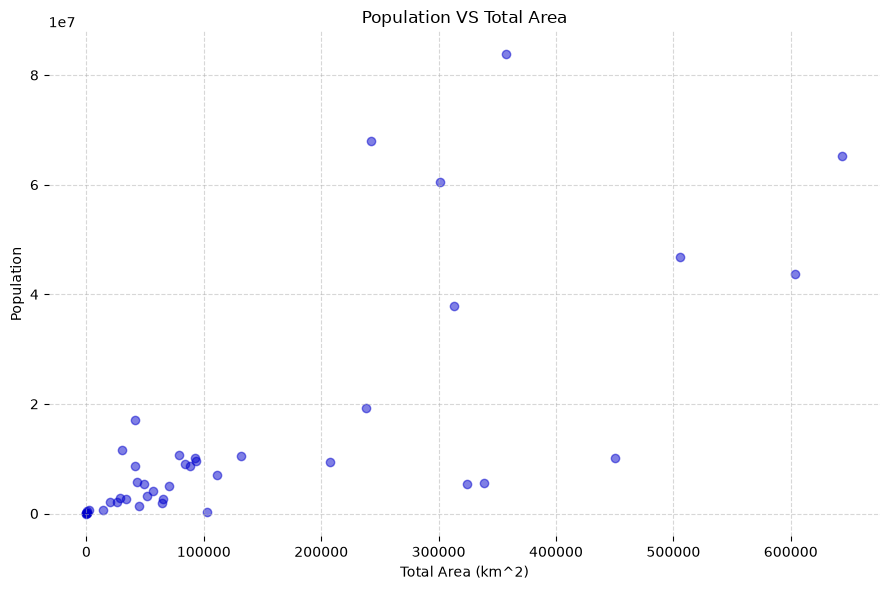

In [187]:
plt.figure(figsize=(9,6)) # increased size for general readability
                          # and consistency with other graphs

plt.scatter(df["area_km2"], 
            df["population"],
            alpha=0.5, 
            color="mediumblue" # medium blue to stand out with some transparency to see overlap
)

plt.title("Population VS Total Area")
plt.xlabel("Total Area (km^2)")
plt.ylabel("Population")
plt.grid(True, linestyle="--", alpha=0.5) # adjusted alpha of grid not to hinder with data
plt.gca().spines[:].set_visible(False) # removed spines for simplicity

plt.tight_layout() # while not strictly necessary for my data, 
                   # tightens layout to make data more concise
plt.show()

#Sources: None

# Box Plot (Improved) #

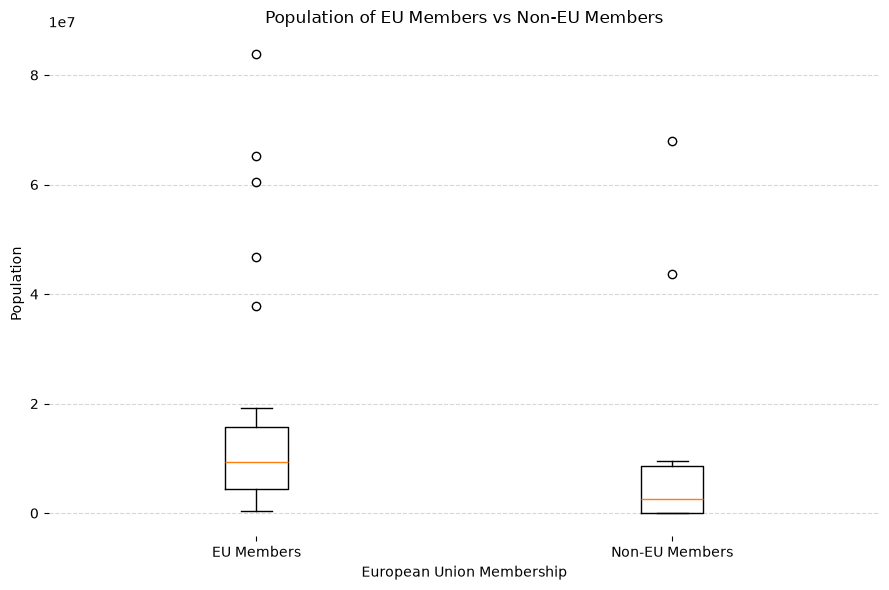

In [188]:
plt.figure(figsize=(9,6)) # increased size for general readability
                          # and consistency with other graphs

plt.boxplot([member, non_member],
    
    tick_labels=["EU Members", "Non-EU Members"], 
          
)

plt.xlabel("European Union Membership")
plt.ylabel("Population")
plt.title("Population of EU Members vs Non-EU Members")
plt.grid(axis="y", linestyle="--", alpha=0.5) # adjusted alpha of grid not to hinder with data
plt.gca().spines[:].set_visible(False) # removed spines for simplicity

plt.tight_layout()
plt.show()

In [189]:
model = ols("population ~ eu_member", data=df).fit()

print(model.summary())

#Sources: Google search to fix variables as seen in 5th working [code] cell.

                            OLS Regression Results                            
Dep. Variable:             population   R-squared:                       0.035
Model:                            OLS   Adj. R-squared:                  0.011
Method:                 Least Squares   F-statistic:                     1.466
Date:                Wed, 18 Nov 2026   Prob (F-statistic):              0.233
Time:                        01:06:38   Log-Likelihood:                -784.83
No. Observations:                  43   AIC:                             1574.
Df Residuals:                      41   BIC:                             1577.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept          9.173e+06   5.08e+0

### **OLS Discussion:** ###

From my understanding, this model shows that [from this dataset] countries in the European Union, on average, have a population ~7.91 million greater than European countries not in the EU. While this disproves my hypothesis, the P-value of 0.233 is quite weak, showing it is not a significant difference.

Sources: https://www.geeksforgeeks.org/machine-learning/interpreting-the-results-of-linear-regression-using-ols-summary/

## **Conclusion:** ##

The key takeaway I got from this dataset was the vast population dispersion across Europe. I do not know enough to say how extreme it is compared to other continents, but it is quite interesting to see.

My findings do not follow my hypothesis as European Countries in the European Union had a higher average population as seen in the OLS results, but indeed it is not a significant difference.

While the boxplot does have the issue of not being able to show "visually more" data than the other graphs, it was the most useful regarding my hypothesis.

As far as I am aware, there are very little limitations of this dataset for my project, but my analysis is quite limited in terms of scope. Contextual issues such as travel and/or potential changes at any given time (since this dataset is not constantly updated) definitely exist. I also do not have verification whether or not the dataset considers all countries and microstates.

I do think taking a more nuanced approach to this data would be optimal to see a more "general" view of the population as even a few small countries can make a large impact on the average.